# Word Sense Disambiguation (WSD) for 'bank'
Word Sense Disambiguation is the task of identifying which sense of a word (i.e. meaning) is used in a sentence, when the word has multiple meanings. We will use the WordNet-based Lesk algorithm to disambiguate 'bank' in different contexts.

In [3]:
import nltk
from nltk.wsd import lesk
from nltk.tokenize import word_tokenize

# Download necessary NLTK data resources including the missing punkt_tab
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

### Performing Disambiguation
We will define two distinct context sentences and run the Lesk algorithm on both to see how the surrounding words guide the algorithm to the correct WordNet definition.

In [6]:
import nltk
from nltk.corpus import stopwords
from nltk.corpus import wordnet as wn
from nltk.tokenize import word_tokenize

nltk.download('stopwords')

def simple_lesk_improved(context_sentence, ambiguous_word, pos=None):
    """
    An improved Lesk algorithm that tokenizes, removes stopwords,
    and finds the best WordNet sense by computing word overlaps.
    """
    context_tokens = set(word_tokenize(context_sentence.lower()))
    stop_words = set(stopwords.words('english'))
    # Remove punctuation and stopwords from the context
    context_words = {w for w in context_tokens if w.isalnum() and w not in stop_words}

    best_sense = None
    max_overlap = -1

    # Get all candidate synsets for the ambiguous word
    synsets = wn.synsets(ambiguous_word, pos=pos)

    for sense in synsets:
        # Tokenize definition and examples
        def_tokens = word_tokenize(sense.definition().lower())
        example_tokens = []
        for ex in sense.examples():
            example_tokens.extend(word_tokenize(ex.lower()))

        # Combine definition and examples
        sense_words = set(def_tokens + example_tokens) - stop_words
        sense_words = {w for w in sense_words if w.isalnum()}

        # Calculate overlap
        overlap = len(context_words.intersection(sense_words))

        if overlap > max_overlap:
            max_overlap = overlap
            best_sense = sense

    return best_sense

def disambiguate_word(sentence, target_word):
    sense = simple_lesk_improved(sentence, target_word, pos='n')
    print(f"Sentence: \"{sentence}\"")
    if sense:
        print(f"Disambiguated Sense: {sense.name()}")
        print(f"Definition: {sense.definition()}")
    else:
        print("No matching sense found.")
    print("-" * 50)

# Context 1: Financial context
sentence_financial = "I went to the bank to deposit my paycheck and withdraw some cash."
disambiguate_word(sentence_financial, 'bank')

# Context 2: Nature/Geographical context
sentence_river = "We sat on the grassy bank of the river and watched the water flow by."
disambiguate_word(sentence_river, 'bank')

Sentence: "I went to the bank to deposit my paycheck and withdraw some cash."
Disambiguated Sense: bank.n.10
Definition: a flight maneuver; aircraft tips laterally about its longitudinal axis (especially in turning)
--------------------------------------------------
Sentence: "We sat on the grassy bank of the river and watched the water flow by."
Disambiguated Sense: bank.n.01
Definition: sloping land (especially the slope beside a body of water)
--------------------------------------------------


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Visualizing the Word Overlaps (How the Algorithm Decides)

Let's analyze why the algorithm behaved this way by looking at the exact overlaps between the words in our sentences and the definitions of the two primary senses of "bank":
1. **Financial Institution (`bank.n.02` / `depository_financial_institution.n.01`)**
2. **River Slope (`bank.n.01`)**

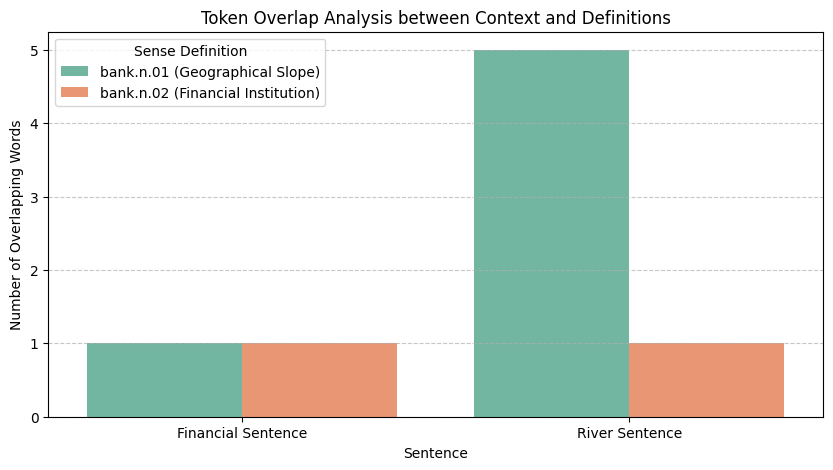

,Sentence,Sense Definition,Overlap Count,Overlapping Words
0,Financial Sentence,bank.n.01 (Geographical Slope),1,bank
1,Financial Sentence,bank.n.02 (Financial Institution),1,bank
2,River Sentence,bank.n.01 (Geographical Slope),5,"water, river, sat, bank, watched"
3,River Sentence,bank.n.02 (Financial Institution),1,bank


In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.corpus import wordnet as wn

# Extract clean context words from both sentences
stop_words = set(stopwords.words('english'))

words_financial = {w.lower() for w in word_tokenize(sentence_financial) if w.isalnum() and w.lower() not in stop_words}
words_river = {w.lower() for w in word_tokenize(sentence_river) if w.isalnum() and w.lower() not in stop_words}

# Define the target senses we want to compare against
senses_to_compare = {
    'bank.n.01 (Geographical Slope)': wn.synset('bank.n.01'),
    'bank.n.02 (Financial Institution)': wn.synset('bank.n.02')
}

# Calculate exact overlaps
data = []
for sentence_name, sentence_words in [('Financial Sentence', words_financial), ('River Sentence', words_river)]:
    for sense_label, synset in senses_to_compare.items():
        sense_tokens = word_tokenize(synset.definition().lower())
        for ex in synset.examples():
            sense_tokens.extend(word_tokenize(ex.lower()))

        # Corrected the condition to properly filter stopwords and check isalnum
        sense_words = {w.lower() for w in sense_tokens if w.isalnum() and w.lower() not in stop_words}

        overlapping_words = sentence_words.intersection(sense_words)
        overlap_count = len(overlapping_words)

        data.append({
            'Sentence': sentence_name,
            'Sense Definition': sense_label,
            'Overlap Count': overlap_count,
            'Overlapping Words': ", ".join(overlapping_words) if overlapping_words else "None"
        })

df_overlap = pd.DataFrame(data)

# Plotting the results
plt.figure(figsize=(10, 5))
sns.barplot(x='Sentence', y='Overlap Count', hue='Sense Definition', data=df_overlap, palette='Set2')
plt.title('Token Overlap Analysis between Context and Definitions')
plt.ylabel('Number of Overlapping Words')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Display the structured table
display(df_overlap)

### How Context Words Help
The Lesk algorithm relies on word overlaps between the context sentence and the definitions/examples of the word's various senses in WordNet:
1. **Financial Sense:** Words like *deposit*, *paycheck*, *withdraw*, and *cash* share conceptual overlap with WordNet definitions containing financial terms.
2. **River/Geographical Sense:** Words like *river*, *grassy*, and *water* overlap with WordNet definitions related to slopes, land, or bodies of water.